<div style="background-color: rgba(235, 104, 52, 0.12); border-left: 10px solid #eb6834; border-radius: 6px; padding: 6px 20px;">

# Predictive maintenance of turbofan engines

<p style="font-size: 1.5em; font-weight: 600; margin: 0 0 8px 0;">2. Modelling and evaluation</p>

</div>

<div style="margin-top: 10px; padding: 0 4px;">

**Machine Learning I, ING2-BDML, Project 1** | Dataset: NASA C-MAPSS, subset FD001

</div>

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px; margin-top: 14px;">

**Goal of the project.** Predict, for each flight of an engine, whether the engine is about to fail.

**Goal of this notebook.** This is the second stage of the project: train the models, compare them, and evaluate the best one on the test engines. It starts from the decisions taken at the end of the exploration notebook ([1. Data exploration](ml1_project_nasa_fd001_cmapss_engine_failure_classifyer_data_exploration.ipynb), section 12).

</div>

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px; margin-top: 14px;">

**What we inherit from the exploration**

| Decision | Value |
|---|---|
| Label | $y = 1$ if $\text{RUL} \le 30$, else $0$ (15% of the training rows are $y = 1$) |
| Features | the 14 sensors `s2`, `s3`, `s4`, `s7`, `s8`, `s9`, `s11`, `s12`, `s13`, `s14`, `s15`, `s17`, `s20`, `s21`; `s9` and `s14` are **to be tested** |
| Not features | `unit`, `cycle`, the settings, `RUL` and `y` (target leakage) |
| Validation | all the rows of an engine on the same side: `GroupKFold` with `unit` as groups |
| Scaling | standardise before k-NN, SVM and logistic regression |
| Metrics | recall, precision, F1 and AUC, not accuracy alone; the costly error is the missed failure |
| Models | compare linear and non-linear models |
| Final test | one prediction per test engine, at its last recorded row (100 predictions) |

</div>

---

### Roadmap

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px;">

| Step | Section | Question it answers |
|---|---|---|
| 1 | Rebuilding the data and the protocol | How do we measure a model fairly? |
| 2 | The baseline | What does a useless model score? |
| 3 | Comparing the models | Which families of models work on this problem? |
| 4 | Do we keep `s9` and `s14`? | Does removing the two weakest sensors change the scores? |
| 5 | Handling the imbalance | Does weighting the classes help? |
| 6 | Tuning the models | How far can each model go? |
| 7 | Choosing the model and the alarm threshold | Which model, and from which score do we raise the alarm? |
| 8 | Final evaluation on the test engines | How good is the chosen model on engines it has never seen? |
| 9 | Where does the model fail? | Are the errors random, or do they follow a pattern? |
| 10 | What we learned | What is the answer to the project, and what are its limits? |

</div>

---

<a id="toc"></a>

### Table of contents

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px;">

- <a href="#section-0">0. Setup</a>
- <a href="#section-1">1. Rebuilding the data and the protocol</a>
- <a href="#section-2">2. The baseline</a>
- <a href="#section-3">3. Comparing the models</a>
- <a href="#section-4">4. Do we keep `s9` and `s14`?</a>
- <a href="#section-5">5. Handling the imbalance</a>
- <a href="#section-6">6. Tuning the models</a>
- <a href="#section-7">7. Choosing the model and the alarm threshold</a>
- <a href="#section-8">8. Final evaluation on the test engines</a>
- <a href="#section-9">9. Where does the model fail?</a>
- <a href="#section-10">10. What we learned</a>

</div>

<a id="section-0"></a>

<div style="background-color: rgba(31, 119, 180, 0.14); border-left: 8px solid #1f77b4; border-radius: 6px; padding: 2px 16px; margin-top: 28px;">

## 0. Setup

</div>

In [1]:
# Libraries: data handling (numpy, pandas), figures (plotly) and models (scikit-learn)
import time
import warnings

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score, fbeta_score,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")      # keeps the notebook readable: scikit-learn warns when a model never predicts class 1

# Where the data files are, and the choices made in the exploration notebook
DATA_DIR = "cmapss_nasa_turbo_engine_6_data/CMAPSSData/"
W = 30                      # warning window, in cycles (section 5 of the exploration notebook)
N_FOLDS = 5                 # number of folds of the cross-validation
SEED = 0                    # makes every random choice reproducible

# Colours and theme shared by all the figures
BLUE, ORANGE, GREY, GREEN = "#2a78d6", "#eb6834", "#898781", "#1a7f64"
TEMPLATE = "plotly_white"
pd.set_option("display.max_columns", 30)

<a id="section-1"></a>

<div style="background-color: rgba(31, 119, 180, 0.14); border-left: 8px solid #1f77b4; border-radius: 6px; padding: 2px 16px; margin-top: 28px;">

## 1. Rebuilding the data and the protocol

</div>

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px; margin-top: 14px;">

- **Goal**: Rebuild the training and test tables exactly as decided in the exploration, and fix how every model will be measured.
- **Why**: A fair comparison needs the same data, the same folds and the same metrics for every model, defined once.

<a href="#conclusion-1" style="display: inline-block; padding: 4px 14px; border-radius: 6px; background-color: #8250df; color: white; text-decoration: none; font-weight: 600;">Go to the conclusion of this section</a>

</div>

<div class="section-plan" style="margin-top: 14px; padding: 0 4px;">

<p style="text-align: center;"><b>Plan of the section</b></p>

| Step | What we do |
|---|---|
| [1.1](#sub-1-1) | [Loading the data, the label and the features](#sub-1-1) |
| [1.2](#sub-1-2) | [The evaluation protocol](#sub-1-2) |
| [1.3](#conclusion-1) | [Conclusion](#conclusion-1) |

</div>

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px; margin-top: 14px;">

**Context and method**

The code of this section repeats, in short, what the exploration notebook did (sections 1, 3 and 5), so that this notebook runs on its own.

</div>

<a id="sub-1-1"></a>

---

### 1.1 Loading the data, the label and the features

In [2]:
# The files have no header: we name the 26 columns ourselves
SETTINGS = ["setting_1", "setting_2", "setting_3"]
SENSORS = [f"s{i}" for i in range(1, 22)]
COLUMNS = ["unit", "cycle"] + SETTINGS + SENSORS

def load_cmapss(filename):
    """Read one C-MAPSS file: space-separated, no header, 26 columns."""
    return pd.read_csv(DATA_DIR + filename, sep=r"\s+", header=None, names=COLUMNS)

train = load_cmapss("train_FD001.txt")
test = load_cmapss("test_FD001.txt")
rul_test = pd.read_csv(DATA_DIR + "RUL_FD001.txt", header=None, names=["RUL"])
rul_test["unit"] = rul_test.index + 1      # line i of the file = test engine i

# Training label: RUL = T_fail - t, then y = 1 if RUL <= W
train["RUL"] = train.groupby("unit")["cycle"].transform("max") - train["cycle"]
train["y"] = (train["RUL"] <= W).astype(int)

# Test label: RUL(t) = (t_last - t) + RUL_file, then y = 1 if RUL <= W
last_cycle = test.groupby("unit")["cycle"].transform("max")
test["RUL"] = (last_cycle - test["cycle"]) + test["unit"].map(rul_test.set_index("unit")["RUL"])
test["y"] = (test["RUL"] <= W).astype(int)

# The 14 informative sensors decided in section 11 of the exploration notebook
FEATURES_14 = ["s2", "s3", "s4", "s7", "s8", "s9", "s11", "s12", "s13", "s14", "s15", "s17", "s20", "s21"]
FEATURES_12 = [s for s in FEATURES_14 if s not in ("s9", "s14")]       # the same without the two weakest sensors

# What the models learn from, and what they are finally evaluated on
y_train, groups = train["y"], train["unit"]
test_last = test.groupby("unit").tail(1)           # last recorded row of each test engine: 100 rows

# Checks against the numbers of the exploration notebook
assert len(train) == 20631 and train["y"].sum() == 3100 and len(test) == 13096
assert len(test_last) == 100 and test_last["y"].sum() == 25
print(f"Train      : {len(train):>6,} rows, {train['unit'].nunique()} engines, {train['y'].mean() * 100:.1f}% with y = 1")
print(f"Test (all) : {len(test):>6,} rows, {test['unit'].nunique()} engines, {test['y'].mean() * 100:.1f}% with y = 1")
print(f"Test (last): {len(test_last):>6,} rows, {test_last['unit'].nunique()} engines, {test_last['y'].mean() * 100:.1f}% with y = 1")

Train      : 20,631 rows, 100 engines, 15.0% with y = 1
Test (all) : 13,096 rows, 100 engines, 2.5% with y = 1
Test (last):    100 rows, 100 engines, 25.0% with y = 1


<div style="background-color: rgba(210, 153, 34, 0.12); border-left: 4px solid #d29922; border-radius: 4px; padding: 4px 16px; margin-top: 8px;">

**Interpretation.**


- The numbers match the exploration: 20,631 training rows with 15.0% of $y = 1$, 13,096 test rows with 2.5%, and 100 test engines reduced to their last row with 25%.
- The three balances differ: 15% in training, 2.5% over all the test rows, 25% at the last row of the test engines. A **precision** measured in one setting cannot be compared with one measured in another, because precision depends on how common the positives are. Recall and AUC do not have this problem.

</div>

<a id="sub-1-2"></a>

---

### 1.2 The evaluation protocol

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px;">

Every model of this notebook is measured in the same way.

- **Grouped cross-validation.** `GroupKFold` with 5 folds and `unit` as groups: each fold holds 20 engines **with all their rows**, which the model has never seen ([section 4.3 of the exploration](ml1_project_nasa_fd001_cmapss_engine_failure_classifyer_data_exploration.ipynb)). The engines are shuffled once per seed.
- **Metrics.** At the default threshold of the model: **recall** (share of imminent failures detected), **precision** (share of alarms that are real), **F1** (their balance). Independent of any threshold: **AUC** (can the model rank an imminent failure above a healthy row?) and **average precision, AP** (the area under the precision-recall curve, the metric the most sensitive to the minority class).
- **The test engines are not touched** until [section 8](#section-8): every choice (model, hyperparameters, threshold) is made on the cross-validation only.

</div>

In [3]:
def get_score(model, X):
    """Continuous score of the class 1: the probability when the model has one, else its decision function."""
    return model.predict_proba(X)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X)

def default_threshold(model):
    """Natural threshold of the score: 0.5 for a probability, 0 for a decision function (the SVM)."""
    return 0.5 if hasattr(model, "predict_proba") else 0.0

def metrics(y_true, score, threshold):
    """The six measures of a model, from its score and an alarm threshold."""
    pred = (score >= threshold).astype(int)
    return {"accuracy": accuracy_score(y_true, pred),
            "recall": recall_score(y_true, pred),
            "precision": precision_score(y_true, pred, zero_division=0),
            "f1": f1_score(y_true, pred, zero_division=0),
            "auc": roc_auc_score(y_true, score),
            "ap": average_precision_score(y_true, score)}

def cross_validate(model, features, seed=SEED):
    """Grouped 5-fold CV. Returns the metrics of each fold and the out-of-fold score of every training row."""
    splitter = GroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=seed)
    oof, rows = np.zeros(len(train)), []
    for fit_idx, val_idx in splitter.split(train, y_train, groups):
        fitted = clone(model)
        start = time.time()
        fitted.fit(train.iloc[fit_idx][features], y_train.iloc[fit_idx])
        seconds = time.time() - start
        score = get_score(fitted, train.iloc[val_idx][features])
        oof[val_idx] = score
        rows.append({**metrics(y_train.iloc[val_idx], score, default_threshold(fitted)), "seconds": seconds})
    return pd.DataFrame(rows), oof

def show(results, order=("recall", "precision", "f1", "auc", "ap")):
    """One line per model: mean (std) over the folds."""
    table = pd.DataFrame({name: {m: f"{f[m].mean():.3f} ({f[m].std():.3f})" for m in order} for name, f in results.items()}).T
    table["fit time (s)"] = [round(f["seconds"].mean(), 2) for f in results.values()]
    return table

<div style="background-color: rgba(210, 153, 34, 0.12); border-left: 4px solid #d29922; border-radius: 4px; padding: 4px 16px; margin-top: 8px;">

**Interpretation.**


- Every score of the next sections is measured on engines the model did not see while learning, as the exploration required.
- The functions are written once and used for every model: a difference between two models can only come from the models.

</div>

---

<a id="conclusion-1"></a>

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px;">

### 1.3 Conclusion

**Goal of the section**: Rebuild the data and fix how every model is measured.

**What we found.**
- **Same data as the exploration.** 20,631 training rows (15% with $y = 1$), 13,096 test rows, and 100 test engines reduced to their last row (25% with $y = 1$).
- **Two feature sets.** The 14 sensors, and the same without `s9` and `s14` (12 sensors), to settle the question left open in the exploration.
- **One protocol.** 5 folds grouped by engine, the same function for every model, and the test engines kept for the end.

**Link with the other sections.** The protocol is used from [section 2](#section-2) onwards.

<a href="#section-1">Back to the start of the section</a>

</div>

<a id="section-2"></a>

<div style="background-color: rgba(31, 119, 180, 0.14); border-left: 8px solid #1f77b4; border-radius: 6px; padding: 2px 16px; margin-top: 28px;">

## 2. The baseline

</div>

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px; margin-top: 14px;">

- **Goal**: Measure what a model that learns nothing scores.
- **Why**: A score only means something against a reference. The exploration warned that accuracy is misleading on these imbalanced classes: we check it.

<a href="#conclusion-2" style="display: inline-block; padding: 4px 14px; border-radius: 6px; background-color: #8250df; color: white; text-decoration: none; font-weight: 600;">Go to the conclusion of this section</a>

</div>

<div class="section-plan" style="margin-top: 14px; padding: 0 4px;">

<p style="text-align: center;"><b>Plan of the section</b></p>

| Step | What we do |
|---|---|
| [2.1](#sub-2-1) | [A model that always answers "healthy"](#sub-2-1) |
| [2.2](#conclusion-2) | [Conclusion](#conclusion-2) |

</div>

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px; margin-top: 14px;">

**Context and method**

`DummyClassifier(strategy="prior")` ignores the sensors and always answers the most frequent class, 0.

</div>

<a id="sub-2-1"></a>

---

### 2.1 A model that always answers "healthy"

In [4]:
# The model that ignores the sensors
baseline_folds, _ = cross_validate(DummyClassifier(strategy="prior"), FEATURES_14)
baseline = baseline_folds.mean()

# Its measures
print(f"Accuracy : {baseline['accuracy'] * 100:.1f}%   <- looks good")
print(f"Recall   : {baseline['recall'] * 100:.1f}%    <- not a single failure detected")
print(f"AUC      : {baseline['auc']:.2f}    <- a coin toss")
print(f"AP       : {baseline['ap']:.3f}   <- equal to the share of y = 1: this is the floor of AP")

Accuracy : 85.0%   <- looks good
Recall   : 0.0%    <- not a single failure detected
AUC      : 0.50    <- a coin toss
AP       : 0.150   <- equal to the share of y = 1: this is the floor of AP


<div style="background-color: rgba(210, 153, 34, 0.12); border-left: 4px solid #d29922; border-radius: 4px; padding: 4px 16px; margin-top: 8px;">

**Interpretation.**


- The model that detects nothing has an **accuracy of 85.0%**, a **recall of 0%** and an **AUC of 0.50**. This confirms the warning of the exploration: accuracy cannot be used to judge the models.
- Its **AP is 0.150**, the share of $y = 1$. Any model that learns something must sit well above it.

</div>

---

<a id="conclusion-2"></a>

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px;">

### 2.2 Conclusion

**Goal of the section**: Measure what a model that learns nothing scores.

**What we found.**
- **Accuracy is misleading.** A model that detects nothing reaches 85% of accuracy.
- **The references to beat.** AUC = 0.5 and AP = 0.15 (the share of $y = 1$).
- **From now on we read recall, precision, F1, AUC and AP**, as announced in the exploration.

**Link with the other sections.** The models of [section 3](#section-3) are compared on these metrics.

<a href="#section-2">Back to the start of the section</a>

</div>

<a id="section-3"></a>

<div style="background-color: rgba(31, 119, 180, 0.14); border-left: 8px solid #1f77b4; border-radius: 6px; padding: 2px 16px; margin-top: 28px;">

## 3. Comparing the models

</div>

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px; margin-top: 14px;">

- **Goal**: Train seven models from different families with their default settings and compare them on the grouped cross-validation.
- **Why**: The exploration found a curved link between the sensors and the RUL, overlapping classes and redundant sensors: we do not know in advance which family copes best, so we try several.

<a href="#conclusion-3" style="display: inline-block; padding: 4px 14px; border-radius: 6px; background-color: #8250df; color: white; text-decoration: none; font-weight: 600;">Go to the conclusion of this section</a>

</div>

<div class="section-plan" style="margin-top: 14px; padding: 0 4px;">

<p style="text-align: center;"><b>Plan of the section</b></p>

| Step | What we do |
|---|---|
| [3.1](#sub-3-1) | [The seven models](#sub-3-1) |
| [3.2](#sub-3-2) | [Cross-validated scores](#sub-3-2) |
| [3.3](#sub-3-3) | [Precision-recall curves](#sub-3-3) |
| [3.4](#conclusion-3) | [Conclusion](#conclusion-3) |

</div>

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px; margin-top: 14px;">

**Context and method**

| Family | Model | Why it is in the comparison |
|---|---|---|
| Linear | Logistic regression | A baseline suggested by the bell-shaped distributions; needs standardisation |
| Probabilistic | Gaussian Naive Bayes | The other baseline suggested by the distributions; it assumes independent sensors, which they are not |
| Distance | k-NN | Non-linear, no assumption on the shape of the link; needs standardisation |
| Kernel | SVM (RBF kernel) | Non-linear boundary; needs standardisation |
| Trees | Decision tree | Simple, readable non-linear model |
| Ensembles | Random forest, gradient boosting | Non-linear, robust to redundant sensors |

Where the model accepts it, the classes are **weighted** (`class_weight="balanced"`) so that a missed failure costs more than a false alarm. [Section 5](#section-5) checks what this does.

</div>

<a id="sub-3-1"></a>

---

### 3.1 The seven models

In [5]:
def make_models(class_weight="balanced"):
    """The seven models with their default settings. Distance and linear models come with a standardisation step."""
    scaled = lambda model: Pipeline([("scale", StandardScaler()), ("clf", model)])
    return {
        "Logistic regression": scaled(LogisticRegression(class_weight=class_weight, max_iter=1000)),
        "Naive Bayes": scaled(GaussianNB()),
        "k-NN": scaled(KNeighborsClassifier(n_neighbors=25)),
        "SVM (RBF)": scaled(SVC(kernel="rbf", class_weight=class_weight)),
        "Decision tree": DecisionTreeClassifier(max_depth=6, class_weight=class_weight, random_state=SEED),
        "Random forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight=class_weight,
                                                n_jobs=-1, random_state=SEED),
        "Gradient boosting": HistGradientBoostingClassifier(class_weight=class_weight, random_state=SEED),
    }

models = make_models()
print(f"{len(models)} models: {', '.join(models)}")

7 models: Logistic regression, Naive Bayes, k-NN, SVM (RBF), Decision tree, Random forest, Gradient boosting


<a id="sub-3-2"></a>

---

### 3.2 Cross-validated scores

In [6]:
# Grouped cross-validation of every model on the 14 sensors
results, oof_scores = {}, {}
for name, model in models.items():
    results[name], oof_scores[name] = cross_validate(model, FEATURES_14)

# One line per model: mean (standard deviation over the 5 folds)
comparison = show(results)
comparison.sort_values("ap", ascending=False)

,recall,precision,f1,auc,ap,fit time (s)
Naive Bayes,0.965 (0.022),0.702 (0.021),0.813 (0.013),0.990 (0.002),0.952 (0.010),0.01
Logistic regression,0.946 (0.025),0.728 (0.024),0.822 (0.017),0.989 (0.002),0.949 (0.008),0.04
Random forest,0.905 (0.031),0.810 (0.025),0.854 (0.011),0.989 (0.002),0.947 (0.010),0.46
Gradient boosting,0.923 (0.028),0.772 (0.033),0.840 (0.014),0.989 (0.002),0.947 (0.009),0.52
k-NN,0.833 (0.045),0.899 (0.014),0.864 (0.021),0.985 (0.005),0.940 (0.015),0.01
Decision tree,0.937 (0.014),0.665 (0.019),0.777 (0.011),0.967 (0.008),0.875 (0.015),0.07
SVM (RBF),0.961 (0.023),0.707 (0.028),0.814 (0.016),0.980 (0.003),0.863 (0.019),0.86


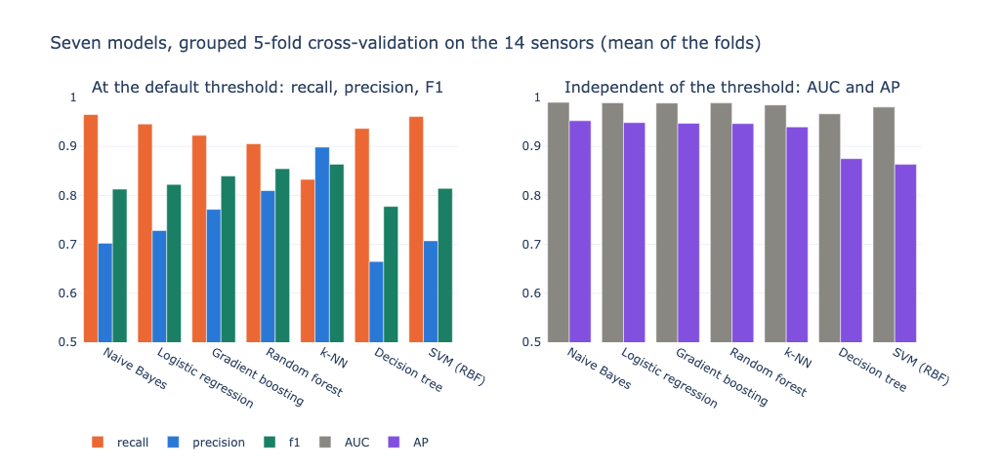

In [7]:
# Figure: threshold-dependent measures on the left, ranking quality on the right
means = pd.DataFrame({name: folds.mean() for name, folds in results.items()}).T.sort_values("ap", ascending=False)
fig = make_subplots(rows=1, cols=2, horizontal_spacing=0.10, subplot_titles=[
    "At the default threshold: recall, precision, F1", "Independent of the threshold: AUC and AP"])
for metric, colour in [("recall", ORANGE), ("precision", BLUE), ("f1", GREEN)]:
    fig.add_bar(x=means.index, y=means[metric], name=metric, marker_color=colour, row=1, col=1)
for metric, colour in [("auc", GREY), ("ap", "#8250df")]:
    fig.add_bar(x=means.index, y=means[metric], name=metric.upper(), marker_color=colour, row=1, col=2)
fig.update_yaxes(range=[0.5, 1.0])
fig.update_layout(template=TEMPLATE, height=480, barmode="group", legend=dict(orientation="h", y=-0.35),
                  title="Seven models, grouped 5-fold cross-validation on the 14 sensors (mean of the folds)")
fig.show()

<div style="background-color: rgba(210, 153, 34, 0.12); border-left: 4px solid #d29922; border-radius: 4px; padding: 4px 16px; margin-top: 8px;">

**Interpretation.**


**Reading the table and the chart.** Each cell is the mean over the 5 folds, with the standard deviation in brackets. Left chart: recall, precision and F1 at the default threshold. Right chart: AUC and AP, which do not depend on a threshold.

**What it shows.**
- **Five models are almost tied on ranking quality**: AUC between 0.985 and 0.990 and AP between 0.940 and 0.952 (Naive Bayes, logistic regression, random forest, gradient boosting, k-NN). The standard deviation of the AP over the folds is about 0.01, so the gaps between them are **inside the noise**.
- **Two models are clearly behind**: the decision tree (AP 0.875) and the SVM with its default settings (AP 0.863).
- **The simple linear model holds its own** (AP 0.949 for logistic regression), which agrees with the exploration: the classes are roughly Gaussian with a shift of the mean, which suits simple models. At this window of 30 cycles, a simple model is enough to exploit the information of the sensors.
- **The differences in F1 are mostly differences of threshold, not of quality.** The models fitted with class weights (logistic regression, SVM, tree, forest, boosting) have a high recall (0.90 to 0.96) and a lower precision (0.67 to 0.81); Naive Bayes, which has no weights, behaves the same way (recall 0.965). k-NN, which cannot be weighted, has the opposite profile (recall 0.83, precision 0.90) with a similar AUC. They sit at different points of the same trade-off, which is why [section 7](#section-7) chooses the threshold explicitly.
- **Cost**: every model is fitted in less than a second, so cost is not a criterion.

</div>

<a id="sub-3-3"></a>

---

### 3.3 Precision-recall curves

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px;">

The table gives one point per model, at its default threshold. The curve gives **all** the points a model can reach by moving the alarm threshold. It is computed on the out-of-fold scores of every training row.

</div>

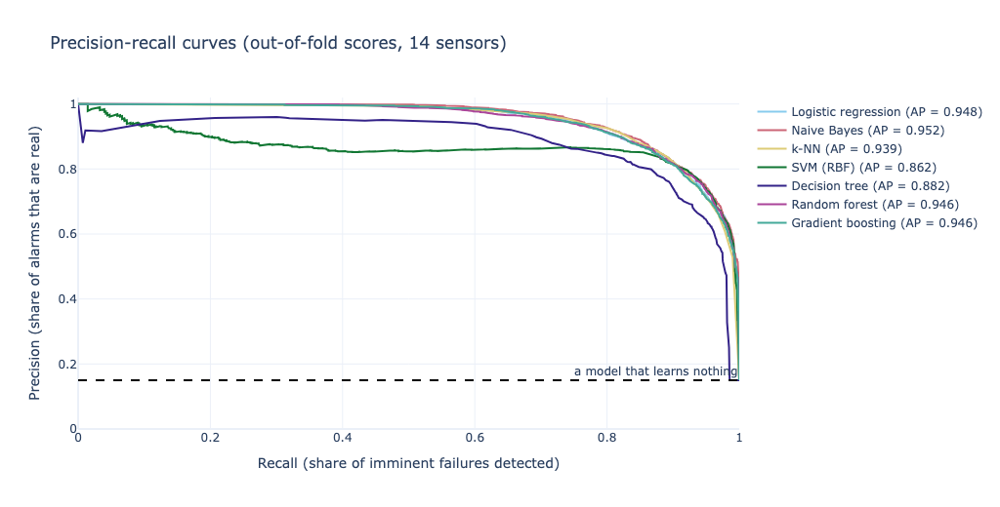

In [8]:
# One curve per model, from its out-of-fold scores
fig = go.Figure()
palette = px.colors.qualitative.Safe
for colour, (name, score) in zip(palette, oof_scores.items()):
    precision, recall, _ = precision_recall_curve(y_train, score)
    fig.add_scatter(x=recall, y=precision, mode="lines", name=f"{name} (AP = {average_precision_score(y_train, score):.3f})",
                    line=dict(color=colour, width=2))
fig.add_hline(y=y_train.mean(), line_dash="dash", line_color="black", annotation_text="a model that learns nothing")
fig.update_layout(template=TEMPLATE, height=520, title="Precision-recall curves (out-of-fold scores, 14 sensors)",
                  xaxis_title="Recall (share of imminent failures detected)", yaxis_title="Precision (share of alarms that are real)",
                  xaxis_range=[0, 1], yaxis_range=[0, 1.02])
fig.show()

<div style="background-color: rgba(210, 153, 34, 0.12); border-left: 4px solid #d29922; border-radius: 4px; padding: 4px 16px; margin-top: 8px;">

**Interpretation.**


- The curves of the five leading models lie **on top of each other** over most of the range, as their AP (in the legend) already said: none has an advantage that the figure shows. The curves of the decision tree and of the default SVM lie below them.
- As the recall grows, the precision falls, and it falls faster at the high-recall end: the last failures to be caught are the rows just inside the boundary $\text{RUL} = 30$, which look like the rows just outside it.
- Each point of a curve is a possible alarm threshold: the choice of the point is a decision, made in [section 7](#section-7).

</div>

---

<a id="conclusion-3"></a>

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px;">

### 3.4 Conclusion

**Goal of the section**: Compare seven models from different families.

**What we found.**

- **Five models are tied** on AUC (0.985 to 0.990) and on AP (0.940 to 0.952), within the noise of the folds (about 0.01).
- **Two models are behind**: the decision tree and the SVM with default settings.
- **A linear model is enough to rank the rows**: logistic regression is among the leaders.
- **Recall and precision differ widely between models of equal quality**, because they sit at different thresholds.


**Link with the other sections.** [Section 4](#section-4) tests the removal of `s9` and `s14`; [section 6](#section-6) tunes the models.

<a href="#section-3">Back to the start of the section</a>

</div>

<a id="section-4"></a>

<div style="background-color: rgba(31, 119, 180, 0.14); border-left: 8px solid #1f77b4; border-radius: 6px; padding: 2px 16px; margin-top: 28px;">

## 4. Do we keep `s9` and `s14`?

</div>

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px; margin-top: 14px;">

- **Goal**: Settle the question left open by the exploration: do the models do better, the same or worse without the two weakest sensors?
- **Why**: In the exploration, `s9` and `s14` were the weakest sensors (|r| of 0.39 and 0.31 with the RUL) and duplicated each other (r = 0.96), but they were weakly correlated with the other twelve. A ranking scores each sensor alone, only a model can tell whether a sensor helps in combination.

<a href="#conclusion-4" style="display: inline-block; padding: 4px 14px; border-radius: 6px; background-color: #8250df; color: white; text-decoration: none; font-weight: 600;">Go to the conclusion of this section</a>

</div>

<div class="section-plan" style="margin-top: 14px; padding: 0 4px;">

<p style="text-align: center;"><b>Plan of the section</b></p>

| Step | What we do |
|---|---|
| [4.1](#sub-4-1) | [Protocol of the test](#sub-4-1) |
| [4.2](#sub-4-2) | [Results](#sub-4-2) |
| [4.3](#sub-4-3) | [Decision](#sub-4-3) |
| [4.4](#conclusion-4) | [Conclusion](#conclusion-4) |

</div>

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px; margin-top: 14px;">

**Context and method**

**Protocol.** For five models, we compare the 14 sensors with the 12 sensors (without `s9` and `s14`). To separate a real difference from the luck of one split, the grouped cross-validation is **repeated with 3 different shuffles of the engines** (15 folds). The two versions are always compared on **the same folds**.

**Decision rule, fixed before looking at the results.** We remove `s9` and `s14` only if the 12-sensor version is **not worse in average precision for at least four models out of five** (a difference above $-0.002$ counts as "not worse"). Otherwise, we keep the 14 sensors.

</div>

<a id="sub-4-1"></a>

---

### 4.1 Protocol of the test

In [9]:
# Five representative models, run on both feature sets and on three shuffles of the engines
tested = ["Logistic regression", "Naive Bayes", "k-NN", "Random forest", "Gradient boosting"]
feature_sets = {"14 sensors": FEATURES_14, "12 sensors (no s9, s14)": FEATURES_12}
SEEDS = [0, 1, 2]

runs = []
for name in tested:
    for set_name, features in feature_sets.items():
        for seed in SEEDS:
            folds, _ = cross_validate(models[name], features, seed=seed)
            runs.append(folds.assign(model=name, features=set_name, seed=seed, fold=range(N_FOLDS)))
runs = pd.concat(runs, ignore_index=True)
print(f"{len(runs)} fits done: {len(tested)} models x {len(feature_sets)} feature sets x {len(SEEDS)} shuffles x {N_FOLDS} folds")

150 fits done: 5 models x 2 feature sets x 3 shuffles x 5 folds


<a id="sub-4-2"></a>

---

### 4.2 Results

In [12]:
# Difference "12 sensors minus 14 sensors" on each of the 15 folds, per model
key = ["model", "seed", "fold"]
wide = runs.pivot_table(index=key, columns="features", values=["ap", "auc", "f1", "recall", "precision"])
rows = []
for name in tested:
    row = {"model": name}
    for metric in ["ap", "auc", "f1"]:
        diff = (wide[metric]["12 sensors (no s9, s14)"] - wide[metric]["14 sensors"]).loc[name]
        row[f"{metric}: 14 sensors"] = wide[metric]["14 sensors"].loc[name].mean()
        row[f"{metric}: difference"] = diff.mean()
        row[f"{metric}: folds where 12 is better"] = f"{(diff > 0).sum()} / {len(diff)}"
    rows.append(row)
feature_test = pd.DataFrame(rows).set_index("model")
feature_test.round(4)

,ap: 14 sensors,ap: difference,ap: folds where 12 is better,auc: 14 sensors,auc: difference,auc: folds where 12 is better,f1: 14 sensors,f1: difference,f1: folds where 12 is better
model,,,,,,,,,
Logistic regression,0.9504,-0.0177,0 / 15,0.9895,-0.0041,0 / 15,0.8220,-0.0220,0 / 15
Naive Bayes,0.9543,-0.0296,0 / 15,0.9904,-0.0074,0 / 15,0.8121,-0.0216,1 / 15
k-NN,0.9414,-0.0207,0 / 15,0.9847,-0.0053,1 / 15,0.8632,-0.0363,0 / 15
Random forest,0.9477,-0.0197,0 / 15,0.9891,-0.0047,0 / 15,0.8526,-0.0262,0 / 15
Gradient boosting,0.9481,-0.0209,0 / 15,0.9887,-0.0048,0 / 15,0.8390,-0.0302,0 / 15


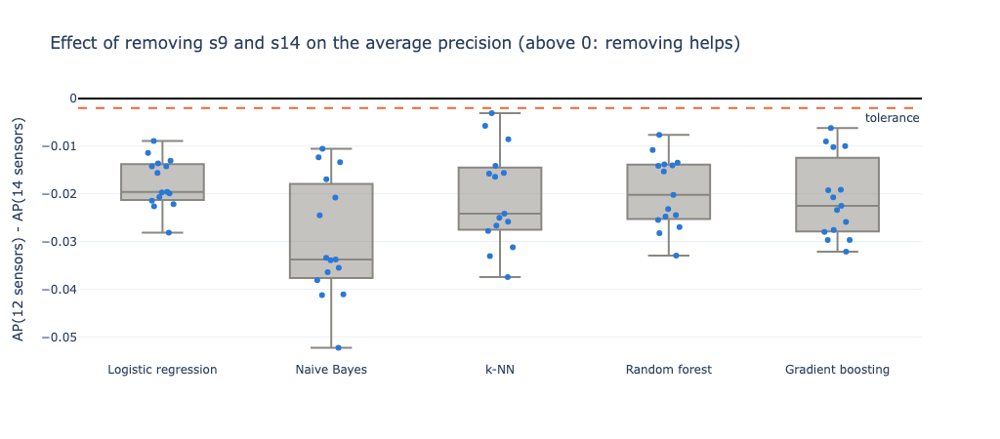

In [13]:
# Figure: difference in AP (12 sensors minus 14 sensors) per model; the points are the 15 folds
fig = go.Figure()
for name in tested:
    diff = (wide["ap"]["12 sensors (no s9, s14)"] - wide["ap"]["14 sensors"]).loc[name]
    fig.add_box(y=diff, name=name, boxpoints="all", jitter=0.4, pointpos=0, marker_color=BLUE, line_color=GREY, showlegend=False)
fig.add_hline(y=0, line_color="black")
fig.add_hline(y=-0.002, line_dash="dash", line_color=ORANGE, annotation_text="tolerance", annotation_position="bottom right")
fig.update_layout(template=TEMPLATE, height=450, yaxis_title="AP(12 sensors) - AP(14 sensors)",
                  title="Effect of removing s9 and s14 on the average precision (above 0: removing helps)")
fig.show()

<div style="background-color: rgba(210, 153, 34, 0.12); border-left: 4px solid #d29922; border-radius: 4px; padding: 4px 16px; margin-top: 8px;">

**Interpretation.**


**Reading the chart.** Each box is the difference in AP between the 12-sensor and the 14-sensor version, over the 15 folds. A box above 0 would mean that removing the two sensors helps; the dashed line is the tolerance of the rule.

**What it shows.**
- **Removing `s9` and `s14` makes every model worse**: the AP drops by 0.018 to 0.030 on average, and the 12-sensor version is better on **0 or 1 fold out of 15** for every model.
- The sign of the difference is the same on (almost) every fold, which matters more than its size because the two versions are compared on the same folds. It is the same for a linear model, a distance model and two tree ensembles: it is not an accident of one family.
- The exploration had guessed it: `s9` and `s14` are weak **alone** (|r| of 0.39 and 0.31 with the RUL), but weakly correlated with the other twelve sensors, so they bring information the others do not. Only a model that combines the sensors could show that.

</div>

<a id="sub-4-3"></a>

---

### 4.3 Decision

In [15]:
# The rule fixed in the introduction of the section
TOLERANCE = -0.002
not_worse = [(wide["ap"]["12 sensors (no s9, s14)"] - wide["ap"]["14 sensors"]).loc[name].mean() > TOLERANCE for name in tested]
DROP_S9_S14 = sum(not_worse) >= 4

FEATURES = FEATURES_12 if DROP_S9_S14 else FEATURES_14
print(f"Models for which removing s9 and s14 is not worse: {sum(not_worse)} out of {len(tested)}")
print(f"{'Decision: remove s9 and s14' if DROP_S9_S14 else 'Decision: keep the 14 sensors'}  ->  {len(FEATURES)} features: {FEATURES}")

Models for which removing s9 and s14 is not worse: 0 out of 5
Decision: keep the 14 sensors  ->  14 features: ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


<div style="background-color: rgba(210, 153, 34, 0.12); border-left: 4px solid #d29922; border-radius: 4px; padding: 4px 16px; margin-top: 8px;">

**Interpretation.**


- **The 14 sensors are kept.** The rule removes the two sensors only if at least four models out of five are not worse without them; here it is 0 out of 5.
- This settles the question the exploration had left open, **in the opposite direction of its "first candidates for removal"**. A ranking of sensors taken one by one is not a good guide to the usefulness of a sensor inside a model.

</div>

---

<a id="conclusion-4"></a>

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px;">

### 4.4 Conclusion

**Goal of the section**: Decide whether `s9` and `s14` are kept.

**What we found.**

- **Removing `s9` and `s14` hurts**: AP drops by 0.018 to 0.030 and AUC by 0.004 to 0.007, for all five models, on 15 folds and 3 shuffles of the engines.
- **Decision: the 14 sensors are kept**, as announced in the exploration.
- **Methodological consequence.** The ranking by correlation of the exploration is a good starting point, but the decision to drop a sensor has to be taken by the models.


**Link with the other sections.** The features chosen here, stored in `FEATURES`, are used in all the following sections.

<a href="#section-4">Back to the start of the section</a>

</div>

<a id="section-5"></a>

<div style="background-color: rgba(31, 119, 180, 0.14); border-left: 8px solid #1f77b4; border-radius: 6px; padding: 2px 16px; margin-top: 28px;">

## 5. Handling the imbalance

</div>

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px; margin-top: 14px;">

- **Goal**: Check what weighting the classes does to each model.
- **Why**: Only 15% of the rows are $y = 1$. Without help, a model can lower its error by caring less about the minority class, which is the one we need to detect.

<a href="#conclusion-5" style="display: inline-block; padding: 4px 14px; border-radius: 6px; background-color: #8250df; color: white; text-decoration: none; font-weight: 600;">Go to the conclusion of this section</a>

</div>

<div class="section-plan" style="margin-top: 14px; padding: 0 4px;">

<p style="text-align: center;"><b>Plan of the section</b></p>

| Step | What we do |
|---|---|
| [5.1](#sub-5-1) | [Weighted versus unweighted classes](#sub-5-1) |
| [5.2](#conclusion-5) | [Conclusion](#conclusion-5) |

</div>

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px; margin-top: 14px;">

**Context and method**

With `class_weight="balanced"`, an error on a $y = 1$ row counts about 5.7 times more than an error on a $y = 0$ row (the imbalance ratio of the exploration). It changes the **default threshold** behaviour of the model; the ranking quality (AUC, AP) is not expected to move much.

</div>

<a id="sub-5-1"></a>

---

### 5.1 Weighted versus unweighted classes

In [16]:
# Same models, with and without class weights, on the chosen features
weighted_models, plain_models = make_models("balanced"), make_models(None)
compared = ["Logistic regression", "Random forest", "Gradient boosting", "Decision tree"]
rows = []
for name in compared:
    for label, family in [("unweighted", plain_models), ("weighted", weighted_models)]:
        folds, _ = cross_validate(family[name], FEATURES)
        rows.append({"model": name, "classes": label, **folds.mean()[["recall", "precision", "f1", "auc", "ap"]]})
imbalance = pd.DataFrame(rows).set_index(["model", "classes"])
imbalance.round(3)

recall  precision     f1    auc     ap
model               classes                                           
Logistic regression unweighted   0.841      0.882  0.861  0.989  0.949
                    weighted     0.946      0.728  0.822  0.989  0.949
Random forest       unweighted   0.842      0.891  0.865  0.989  0.950
                    weighted     0.905      0.810  0.854  0.989  0.947
Gradient boosting   unweighted   0.844      0.877  0.859  0.989  0.947
                    weighted     0.923      0.772  0.840  0.989  0.947
Decision tree       unweighted   0.808      0.867  0.836  0.972  0.897
                    weighted     0.937      0.665  0.777  0.967  0.875

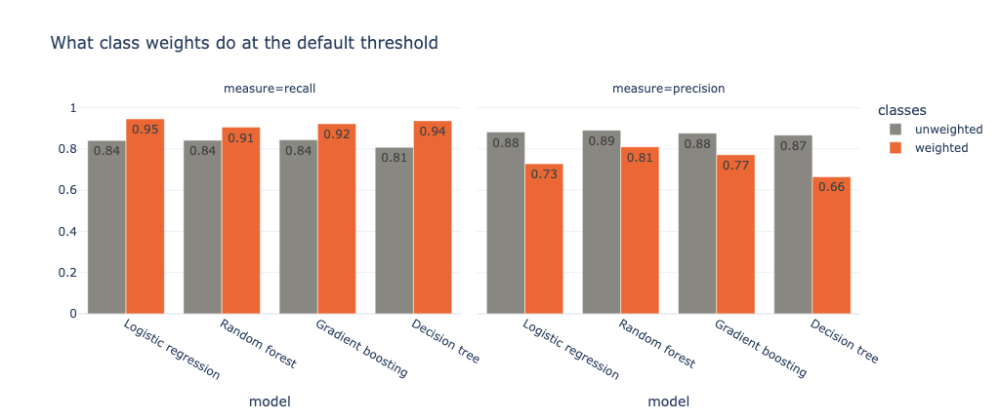

In [17]:
# Figure: recall and precision with and without weights
long = imbalance.reset_index().melt(id_vars=["model", "classes"], value_vars=["recall", "precision"], var_name="measure")
fig = px.bar(long, x="model", y="value", color="classes", facet_col="measure", barmode="group", template=TEMPLATE,
             color_discrete_map={"unweighted": GREY, "weighted": ORANGE}, text_auto=".2f",
             title="What class weights do at the default threshold")
fig.update_layout(height=430); fig.update_yaxes(range=[0, 1.05], title="")
fig.show()

<div style="background-color: rgba(210, 153, 34, 0.12); border-left: 4px solid #d29922; border-radius: 4px; padding: 4px 16px; margin-top: 8px;">

**Interpretation.**


**Reading the table and the chart.** For each model, "weighted" gives an error on a $y = 1$ row a higher cost; "unweighted" treats all rows alike. All measures are taken at the default threshold.

**What it shows.**
- **AUC and AP do not move** (0.989 and 0.947 to 0.950 for the three good models, weighted or not): the weights do not make the model better at ranking the rows.
- **They slide the model along the recall-precision trade-off.** With weights, logistic regression goes from a recall of 0.84 to 0.95 and from a precision of 0.88 to 0.73; the forest and the boosting do the same in a smaller way.
- **The decision tree is the exception**: weights lower its AP (0.897 to 0.875) because a single tree has little room to rank, and it is the model most hurt (precision 0.67).
- **Weights are therefore a way to move the threshold**, which the project can do directly, and more finely, by choosing the threshold ([section 7](#section-7)). We keep the weights, because they put the default threshold in a sensible zone for a problem where missing a failure is the costly error.

</div>

---

<a id="conclusion-5"></a>

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px;">

### 5.2 Conclusion

**Goal of the section**: Check what weighting the classes does.

**What we found.**

- **Class weights do not improve the ranking** (AUC and AP unchanged for the models that matter).
- **They trade precision for recall at the default threshold**: for logistic regression, +0.11 of recall for -0.15 of precision.
- **The same trade can be made, finely, by moving the threshold**, which is what [section 7](#section-7) does.


**Link with the other sections.** The threshold is chosen explicitly in [section 7](#section-7).

<a href="#section-5">Back to the start of the section</a>

</div>

<a id="section-6"></a>

<div style="background-color: rgba(31, 119, 180, 0.14); border-left: 8px solid #1f77b4; border-radius: 6px; padding: 2px 16px; margin-top: 28px;">

## 6. Tuning the models

</div>

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px; margin-top: 14px;">

- **Goal**: Search the hyperparameters of each model and re-evaluate the tuned models on shuffles of the engines never used for tuning.
- **Why**: Default settings are rarely the best ones, and a model must not lose a comparison because it was left untuned.

<a href="#conclusion-6" style="display: inline-block; padding: 4px 14px; border-radius: 6px; background-color: #8250df; color: white; text-decoration: none; font-weight: 600;">Go to the conclusion of this section</a>

</div>

<div class="section-plan" style="margin-top: 14px; padding: 0 4px;">

<p style="text-align: center;"><b>Plan of the section</b></p>

| Step | What we do |
|---|---|
| [6.1](#sub-6-1) | [The search](#sub-6-1) |
| [6.2](#sub-6-2) | [Re-evaluation on new shuffles](#sub-6-2) |
| [6.3](#conclusion-6) | [Conclusion](#conclusion-6) |

</div>

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px; margin-top: 14px;">

**Context and method**

**The search.** A grid search with the grouped 5-fold cross-validation (shuffle `SEED = 0`), scored on **average precision**: it does not depend on a threshold and it is sensitive to the minority class.

**A bias to avoid.** The best score of a grid search is a little optimistic, because the settings were picked on those very folds. The tuned models are therefore **re-scored on two other shuffles of the engines** (seeds 1 and 2), which the search never saw.

</div>

<a id="sub-6-1"></a>

---

### 6.1 The search

In [18]:
# Grid of each model; "clf__" is the name of the model inside its pipeline
grids = {
    "Logistic regression": {"clf__C": [0.01, 0.1, 1, 10, 100]},
    "Naive Bayes": {"clf__var_smoothing": [1e-9, 1e-6, 1e-3, 1e-1]},
    "k-NN": {"clf__n_neighbors": [5, 15, 25, 50, 100], "clf__weights": ["uniform", "distance"]},
    "SVM (RBF)": {"clf__C": [0.1, 1, 10], "clf__gamma": [0.01, 0.03, 0.1]},
    "Decision tree": {"max_depth": [3, 5, 8], "min_samples_leaf": [20, 100]},
    "Random forest": {"min_samples_leaf": [5, 20, 50], "max_features": ["sqrt", 0.5]},
    "Gradient boosting": {"learning_rate": [0.03, 0.1], "max_leaf_nodes": [8, 31], "l2_regularization": [0.0, 10.0]},
}
search_cv = GroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

tuned, search_log = {}, []
for name, grid in grids.items():
    start = time.time()
    search = GridSearchCV(models[name], grid, scoring="average_precision", cv=search_cv, n_jobs=-1, refit=False)
    search.fit(train[FEATURES], y_train, groups=groups)
    tuned[name] = clone(models[name]).set_params(**search.best_params_)
    search_log.append({"model": name, "settings tried": len(search.cv_results_["params"]),
                       "best settings": {k.split("__")[-1]: v for k, v in search.best_params_.items()},
                       "AP of the search": round(search.best_score_, 4), "seconds": round(time.time() - start)})
pd.DataFrame(search_log).set_index("model")

,settings tried,best settings,AP of the search,seconds
model,,,,
Logistic regression,5,{'C': 100},0.9486,3
Naive Bayes,4,{'var_smoothing': 0.1},0.9525,0
k-NN,10,"{'n_neighbors': 100, 'weights': 'distance'}",0.9517,3
SVM (RBF),9,"{'C': 1, 'gamma': 0.01}",0.9532,8
Decision tree,6,"{'max_depth': 8, 'min_samples_leaf': 100}",0.9035,0
Random forest,6,"{'max_features': 'sqrt', 'min_samples_leaf': 5}",0.9467,16
Gradient boosting,8,"{'l2_regularization': 10.0, 'learning_rate': 0...",0.9506,1


<div style="background-color: rgba(210, 153, 34, 0.12); border-left: 4px solid #d29922; border-radius: 4px; padding: 4px 16px; margin-top: 8px;">

**Interpretation.**


- Every model was searched on 4 to 10 combinations of settings (the table gives the exact number), with the average precision as the score.
- **Two remarks on the best settings.** Logistic regression picks $C = 100$, the **edge of the grid**, meaning that it wants almost no regularisation; the score was flat along the grid (0.9486 against about 0.949 by default), so the choice is not important. The SVM picks the smallest `gamma` of its grid (0.01), which hints that its default `gamma` (about 0.07 with 14 sensors) was too large.
- The scores of the search are close for all models except the tree: Naive Bayes, SVM and k-NN all have an AP of about 0.952 to 0.953.

</div>

<a id="sub-6-2"></a>

---

### 6.2 Re-evaluation on new shuffles

In [19]:
# Default and tuned versions of every model, scored on shuffles 1 and 2, which the search never saw
rows, tuned_oof = [], {}
for name in models:
    for label, model in [("default", models[name]), ("tuned", tuned[name])]:
        folds = []
        for seed in [1, 2]:
            f, oof = cross_validate(model, FEATURES, seed=seed)
            folds.append(f)
            if label == "tuned" and seed == 1:
                tuned_oof[name] = oof                     # out-of-fold scores kept for the threshold of section 7
        folds = pd.concat(folds)
        rows.append({"model": name, "version": label, **folds.mean()[["recall", "precision", "f1", "auc", "ap"]],
                     "ap std": folds["ap"].std()})
reeval = pd.DataFrame(rows)
final_cv = reeval[reeval["version"] == "tuned"].set_index("model").drop(columns="version").sort_values("ap", ascending=False)
gain = reeval.pivot(index="model", columns="version", values="ap")
final_cv["AP gain from tuning"] = (gain["tuned"] - gain["default"]).loc[final_cv.index]
final_cv.round(3)

,recall,precision,f1,auc,ap,ap std,AP gain from tuning
model,,,,,,,
Naive Bayes,0.961,0.712,0.815,0.990,0.955,0.009,-0.000
SVM (RBF),0.955,0.722,0.820,0.990,0.955,0.010,0.094
k-NN,0.829,0.904,0.863,0.989,0.953,0.010,0.011
Logistic regression,0.945,0.730,0.822,0.990,0.951,0.011,-0.000
Gradient boosting,0.941,0.741,0.827,0.989,0.951,0.009,0.003
Random forest,0.900,0.812,0.852,0.989,0.948,0.010,0.000
Decision tree,0.939,0.690,0.794,0.980,0.908,0.012,0.025


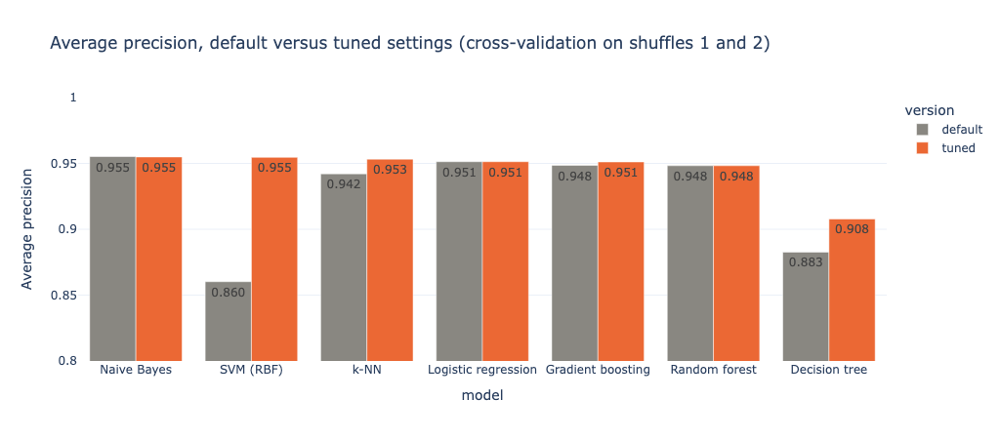

In [20]:
# Figure: AP of every model, default versus tuned (mean of 10 folds)
fig = px.bar(reeval, x="model", y="ap", color="version", barmode="group", template=TEMPLATE, text_auto=".3f",
             color_discrete_map={"default": GREY, "tuned": ORANGE},
             category_orders={"model": final_cv.index.tolist()},
             title="Average precision, default versus tuned settings (cross-validation on shuffles 1 and 2)")
fig.update_layout(height=450, yaxis_title="Average precision"); fig.update_yaxes(range=[0.8, 1.0])
fig.show()

<div style="background-color: rgba(210, 153, 34, 0.12); border-left: 4px solid #d29922; border-radius: 4px; padding: 4px 16px; margin-top: 8px;">

**Interpretation.**


**Reading the table and the chart.** The scores are the mean of 10 folds (2 new shuffles of 5 folds) that the search never saw. "AP gain from tuning" compares the tuned version with the default version on the same folds.

**What it shows.**
- **The ranking is tight**: Naive Bayes and SVM (AP 0.955), k-NN (0.953), logistic regression and gradient boosting (0.951), random forest (0.948). The standard deviation of the AP is about 0.01, so **these six models cannot be told apart**.
- **The decision tree is behind** (AP 0.908), even after tuning (+0.025).
- **Tuning matters little for most models**: gains of 0.000 to 0.003 for Naive Bayes, logistic regression, the forest and the boosting. Their default settings were already good.
- **The SVM benefits the most from tuning (+0.094)**, going from the weakest of the candidates to a tie for first place: a model can lose a comparison only because it was left untuned.
- k-NN gains 0.011, by using many more neighbours (100 instead of 25) with a weighting by distance: the noise of a single row asks for a lot of smoothing.

</div>

---

<a id="conclusion-6"></a>

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px;">

### 6.3 Conclusion

**Goal of the section**: Tune every model and score the tuned versions honestly.

**What we found.**

- **Tuning changes little for four models out of seven** (Naive Bayes, logistic regression, forest, boosting), and a lot for the SVM (+0.094 of AP) and, to a lesser extent, the tree (+0.025) and k-NN (+0.011).
- **Six models end within 0.007 of AP of each other** (0.948 to 0.955), against a noise of about 0.01 between folds: the data does not allow to name a clear winner.
- **The scores are honest**: they were measured on shuffles of the engines never used by the search.


**Link with the other sections.** The best tuned model is chosen in [section 7](#section-7).

<a href="#section-6">Back to the start of the section</a>

</div>

<a id="section-7"></a>

<div style="background-color: rgba(31, 119, 180, 0.14); border-left: 8px solid #1f77b4; border-radius: 6px; padding: 2px 16px; margin-top: 28px;">

## 7. Choosing the model and the alarm threshold

</div>

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px; margin-top: 14px;">

- **Goal**: Pick one model from the cross-validation, then choose the score from which it raises the alarm.
- **Why**: Everything is decided before the test engines are opened, so that the final score is an honest estimate. And the threshold is a real decision: it sets the balance between missed failures and false alarms.

<a href="#conclusion-7" style="display: inline-block; padding: 4px 14px; border-radius: 6px; background-color: #8250df; color: white; text-decoration: none; font-weight: 600;">Go to the conclusion of this section</a>

</div>

<div class="section-plan" style="margin-top: 14px; padding: 0 4px;">

<p style="text-align: center;"><b>Plan of the section</b></p>

| Step | What we do |
|---|---|
| [7.1](#sub-7-1) | [Choosing the model](#sub-7-1) |
| [7.2](#sub-7-2) | [Choosing the threshold](#sub-7-2) |
| [7.3](#conclusion-7) | [Conclusion](#conclusion-7) |

</div>

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px; margin-top: 14px;">

**Context and method**

**Choice of the model.** The tuned model with the highest cross-validated average precision. If several models are within 0.005 of it, we take the **simplest** one (the order of simplicity: logistic regression, Naive Bayes, decision tree, k-NN, SVM, random forest, gradient boosting).

**Choice of the threshold.** A missed failure is more costly than a false alarm, so we maximise the **F2 score**, which counts recall twice as much as precision:

$$F_2 = \frac{5 \times \text{precision} \times \text{recall}}{4 \times \text{precision} + \text{recall}}$$

The threshold is searched on the **out-of-fold** scores of the training engines.

</div>

<a id="sub-7-1"></a>

---

### 7.1 Choosing the model

In [21]:
# Highest AP, then the simplest model among those within 0.005 of it
SIMPLICITY = ["Logistic regression", "Naive Bayes", "Decision tree", "k-NN", "SVM (RBF)", "Random forest",
              "Gradient boosting"]
best_ap = final_cv["ap"].max()
close = [name for name in SIMPLICITY if final_cv.loc[name, "ap"] >= best_ap - 0.005]
CHOSEN = close[0]
print(f"Best AP: {best_ap:.3f} | models within 0.005 of it: {close}")
print(f"Chosen model: {CHOSEN}  ->  {tuned[CHOSEN]}")

Best AP: 0.955 | models within 0.005 of it: ['Logistic regression', 'Naive Bayes', 'k-NN', 'SVM (RBF)', 'Gradient boosting']
Chosen model: Logistic regression  ->  Pipeline(steps=[('scale', StandardScaler()),
                ('clf',
                 LogisticRegression(C=100, class_weight='balanced',
                                    max_iter=1000))])


<div style="background-color: rgba(210, 153, 34, 0.12); border-left: 4px solid #d29922; border-radius: 4px; padding: 4px 16px; margin-top: 8px;">

**Interpretation.**


- **The best tuned AP is 0.955** (Naive Bayes and SVM), and **five models are within 0.005 of it**.
- With such a tie, we apply the rule written beforehand and take the simplest: **logistic regression**, with $C = 100$ and balanced class weights.
- This is also the model that can be **read and checked**: its coefficients say how each standardised sensor moves the score. And it is fitted in a fraction of a second.
- We do not look at the test engines to break the tie.

</div>

<a id="sub-7-2"></a>

---

### 7.2 Choosing the threshold

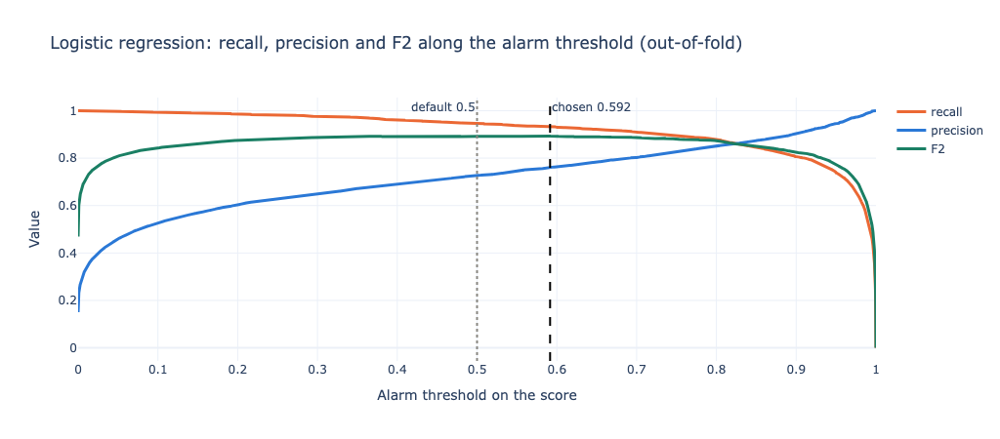

,recall,precision,f1,F2
default (0.5),0.946,0.726,0.822,0.892
chosen (0.592),0.934,0.762,0.839,0.893


In [22]:
# Precision, recall and F2 along the threshold, on the out-of-fold scores of the chosen model
oof = tuned_oof[CHOSEN]
precision, recall, thresholds = precision_recall_curve(y_train, oof)
f2 = 5 * precision[:-1] * recall[:-1] / np.maximum(4 * precision[:-1] + recall[:-1], 1e-12)
THRESHOLD = thresholds[np.argmax(f2)]
DEFAULT = default_threshold(tuned[CHOSEN])

fig = go.Figure()
for values, name, colour in [(recall[:-1], "recall", ORANGE), (precision[:-1], "precision", BLUE), (f2, "F2", GREEN)]:
    fig.add_scatter(x=thresholds, y=values, mode="lines", name=name, line=dict(color=colour, width=3))
fig.add_vline(x=DEFAULT, line_dash="dot", line_color=GREY, annotation_text=f"default {DEFAULT:g}", annotation_position="top left")
fig.add_vline(x=THRESHOLD, line_dash="dash", line_color="black", annotation_text=f"chosen {THRESHOLD:.3f}", annotation_position="top right")
fig.update_layout(template=TEMPLATE, height=450, title=f"{CHOSEN}: recall, precision and F2 along the alarm threshold (out-of-fold)",
                  xaxis_title="Alarm threshold on the score", yaxis_title="Value")
fig.show()

# What the choice changes on the training engines
compare_threshold = pd.DataFrame({f"default ({DEFAULT:g})": metrics(y_train, oof, DEFAULT),
                                  f"chosen ({THRESHOLD:.3f})": metrics(y_train, oof, THRESHOLD)}).T[["recall", "precision", "f1"]]
compare_threshold["F2"] = [fbeta_score(y_train, (oof >= t).astype(int), beta=2) for t in (DEFAULT, THRESHOLD)]
compare_threshold.round(3)

<div style="background-color: rgba(210, 153, 34, 0.12); border-left: 4px solid #d29922; border-radius: 4px; padding: 4px 16px; margin-top: 8px;">

**Interpretation.**


**Reading the chart.** When the threshold goes up, precision rises and recall falls. F2 (green) peaks where recall is high without letting precision collapse. The dotted line is the default threshold, the dashed line the chosen one.

**What it shows.**
- **The F2 curve is very flat around its maximum**: F2 is 0.892 at the default threshold of 0.5 and 0.893 at the chosen threshold of 0.592. On the training engines the choice changes little.
- **What changes is the balance**: recall 0.946 to 0.934, precision 0.726 to 0.762. The chosen threshold trades one point of recall for four points of precision.
- **The threshold is a decision, not a discovery.** If a missed failure costs much more than the F2 assumes, the alarm threshold should be lowered, and the chart shows what it would cost in false alarms.

</div>

---

<a id="conclusion-7"></a>

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px;">

### 7.3 Conclusion

**Goal of the section**: Pick one model and one alarm threshold from the cross-validation only.

**What we found.**

- **Chosen model: logistic regression** (standardised 14 sensors, $C = 100$, balanced class weights), the simplest of the five models tied within 0.005 of the best AP.
- **Chosen threshold: 0.592** on the probability, which maximises F2 on the out-of-fold scores. On the training engines it gives a recall of 0.934 and a precision of 0.762.
- **Both choices are frozen** before the test engines are opened.


**Link with the other sections.** Both choices are frozen: [section 8](#section-8) opens the test engines once.

<a href="#section-7">Back to the start of the section</a>

</div>

<a id="section-8"></a>

<div style="background-color: rgba(31, 119, 180, 0.14); border-left: 8px solid #1f77b4; border-radius: 6px; padding: 2px 16px; margin-top: 28px;">

## 8. Final evaluation on the test engines

</div>

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px; margin-top: 14px;">

- **Goal**: Measure the chosen model on 100 engines it has never seen, and say how reliable that measure is.
- **Why**: The test file is the only data that played no part in any choice: it gives the honest estimate of what the model does on a new engine.

<a href="#conclusion-8" style="display: inline-block; padding: 4px 14px; border-radius: 6px; background-color: #8250df; color: white; text-decoration: none; font-weight: 600;">Go to the conclusion of this section</a>

</div>

<div class="section-plan" style="margin-top: 14px; padding: 0 4px;">

<p style="text-align: center;"><b>Plan of the section</b></p>

| Step | What we do |
|---|---|
| [8.1](#sub-8-1) | [Training on all the training engines](#sub-8-1) |
| [8.2](#sub-8-2) | [Scores on the 100 test engines](#sub-8-2) |
| [8.3](#sub-8-3) | [How reliable are 100 predictions?](#sub-8-3) |
| [8.4](#sub-8-4) | [The test rows beyond the last one](#sub-8-4) |
| [8.5](#conclusion-8) | [Conclusion](#conclusion-8) |

</div>

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px; margin-top: 14px;">

**Context and method**

**Convention of the dataset.** One prediction per test engine, at its **last recorded row**: 100 predictions, 25 of them with $y = 1$.

**Honesty.** The table shows every tuned model for transparency, but **the chosen model is the one of [section 7](#section-7)**: it is not re-chosen on the test score.

</div>

<a id="sub-8-1"></a>

---

### 8.1 Training on all the training engines

In [23]:
# Every tuned model is refitted on the 100 training engines, then scores the test rows
fitted = {name: clone(model).fit(train[FEATURES], y_train) for name, model in tuned.items()}
fitted["Baseline (always healthy)"] = DummyClassifier(strategy="prior").fit(train[FEATURES], y_train)
test_scores = {name: get_score(model, test_last[FEATURES]) for name, model in fitted.items()}
print(f"{len(fitted)} models refitted on {len(train):,} training rows")

8 models refitted on 20,631 training rows


<a id="sub-8-2"></a>

---

### 8.2 Scores on the 100 test engines

In [24]:
# Every model at its default threshold, and the chosen model also at the chosen threshold
y_test = test_last["y"]
rows = {name: metrics(y_test, score, default_threshold(fitted[name])) for name, score in test_scores.items()}
rows[f"{CHOSEN}, chosen threshold {THRESHOLD:.3f} (selected)"] = metrics(y_test, test_scores[CHOSEN], THRESHOLD)
test_table = pd.DataFrame(rows).T[["recall", "precision", "f1", "auc", "ap"]]
test_table.sort_values("ap", ascending=False).round(3)

,recall,precision,f1,auc,ap
Naive Bayes,0.92,0.852,0.885,0.987,0.962
k-NN,0.68,0.895,0.773,0.985,0.957
Random forest,0.80,0.909,0.851,0.984,0.956
SVM (RBF),0.88,0.846,0.863,0.982,0.952
Gradient boosting,0.84,0.840,0.840,0.979,0.945
Logistic regression,0.88,0.815,0.846,0.978,0.944
"Logistic regression, chosen threshold 0.592 (selected)",0.84,0.875,0.857,0.978,0.944
Decision tree,0.88,0.815,0.846,0.970,0.908
Baseline (always healthy),0.00,0.000,0.000,0.500,0.250


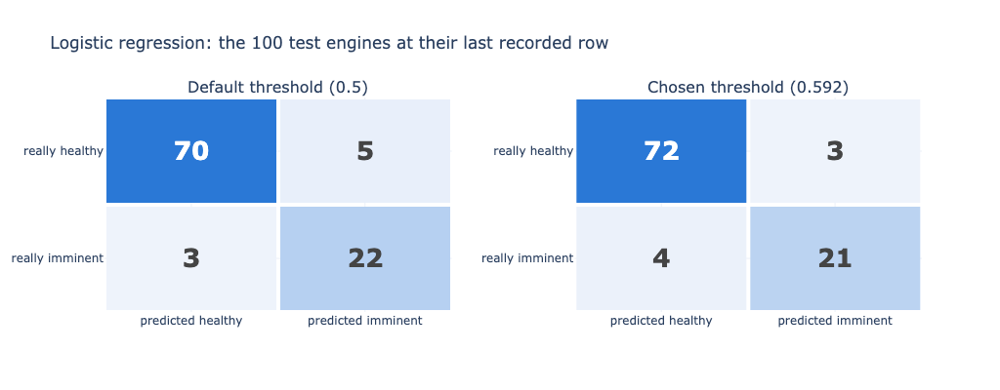

In [25]:
# Confusion matrices of the chosen model: default threshold, then chosen threshold
fig = make_subplots(rows=1, cols=2, horizontal_spacing=0.15, subplot_titles=[f"Default threshold ({DEFAULT:g})", f"Chosen threshold ({THRESHOLD:.3f})"])
for col, threshold in enumerate([DEFAULT, THRESHOLD], start=1):
    cm = confusion_matrix(y_test, (test_scores[CHOSEN] >= threshold).astype(int))
    fig.add_trace(go.Heatmap(z=cm, x=["predicted healthy", "predicted imminent"], y=["really healthy", "really imminent"],
                             text=cm, texttemplate="<b>%{text}</b>", textfont_size=26, colorscale=[[0, "#eef3fb"], [1, BLUE]],
                             showscale=False, xgap=4, ygap=4), row=1, col=col)
fig.update_yaxes(autorange="reversed")
fig.update_layout(template=TEMPLATE, height=400, title=f"{CHOSEN}: the 100 test engines at their last recorded row")
fig.show()

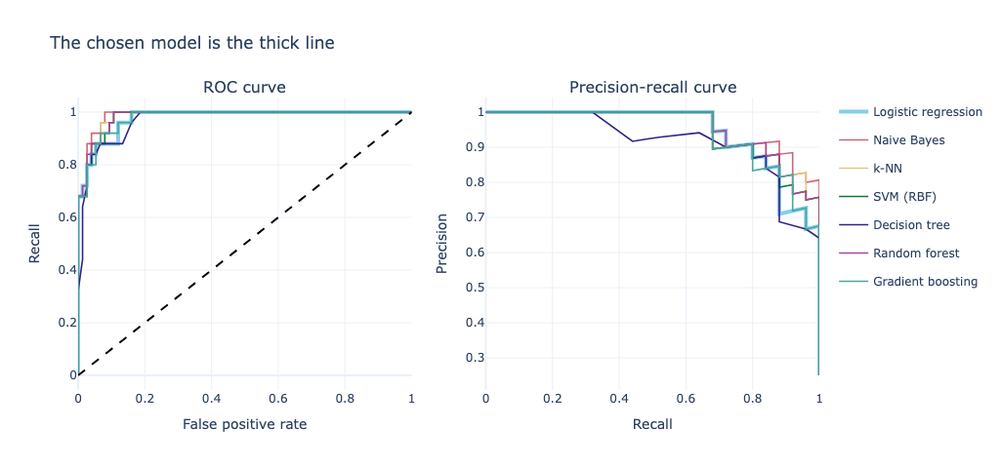

In [26]:
# ROC and precision-recall curves of every tuned model on the 100 test engines
fig = make_subplots(rows=1, cols=2, horizontal_spacing=0.10, subplot_titles=["ROC curve", "Precision-recall curve"])
for colour, (name, score) in zip(px.colors.qualitative.Safe, [(n, s) for n, s in test_scores.items() if n in tuned]):
    width = 4 if name == CHOSEN else 1.6
    fpr, tpr, _ = roc_curve(y_test, score)
    prec, rec, _ = precision_recall_curve(y_test, score)
    fig.add_scatter(x=fpr, y=tpr, mode="lines", name=name, line=dict(color=colour, width=width), legendgroup=name, row=1, col=1)
    fig.add_scatter(x=rec, y=prec, mode="lines", name=name, line=dict(color=colour, width=width), legendgroup=name, showlegend=False, row=1, col=2)
fig.add_scatter(x=[0, 1], y=[0, 1], mode="lines", line=dict(color="black", dash="dash"), showlegend=False, row=1, col=1)
fig.update_xaxes(title_text="False positive rate", row=1, col=1); fig.update_yaxes(title_text="Recall", row=1, col=1)
fig.update_xaxes(title_text="Recall", row=1, col=2); fig.update_yaxes(title_text="Precision", row=1, col=2)
fig.update_layout(template=TEMPLATE, height=480, title="The chosen model is the thick line")
fig.show()

<div style="background-color: rgba(210, 153, 34, 0.12); border-left: 4px solid #d29922; border-radius: 4px; padding: 4px 16px; margin-top: 8px;">

**Interpretation.**


**Reading the table.** The test set is made of 100 engines, 25 of them with $y = 1$. The chosen model is the line marked with a star; it is shown at its default threshold (the plain line) and at the chosen threshold.

**What it shows.**
- **The chosen model detects 21 of the 25 engines about to fail and raises 3 false alarms on 75 healthy engines**: recall 0.84, precision 0.875, F1 0.857, AUC 0.978. The baseline detects none.
- **The chosen threshold does what it was meant to do**: compared with the default threshold (recall 0.88, precision 0.815: 22 detected, 5 false alarms), it gives up one detection and removes two false alarms. This small change was predicted by the cross-validation (recall -1 point, precision +4 points), but on 100 engines one engine is 4 points of recall, so the figures cannot be read finer than that.
- **The other models are close in ranking**: AUC from 0.978 to 0.987 and AP from 0.944 to 0.962 for the six leaders; the decision tree is again last (AP 0.908). **The chosen model is the lowest of the six in AP on the test engines (0.944), while Naive Bayes is the highest (0.962)**. We do not change the choice: a gap of 0.018 in AP on 25 positives is smaller than the confidence interval of the next step, and picking the best on the test would make the final score optimistic.
- **k-NN shows a recall of 0.68 at its default threshold**: it cannot be given class weights, so its 0.5 threshold is too strict. Its AUC (0.985) shows that its ranking is as good as the others'; with a lower threshold it would catch up.

</div>

<a id="sub-8-3"></a>

---

### 8.3 How reliable are 100 predictions?

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px;">

With 100 engines and only 25 of them at risk, one engine moves recall by 4 points. We measure the uncertainty with a **bootstrap**: the 100 engines are redrawn with replacement 2,000 times, and the score is recomputed each time. The range holding 95% of the draws is the **95% confidence interval**.

</div>

In [24]:
# Bootstrap over the test engines: the chosen model at the chosen threshold
rng = np.random.default_rng(SEED)
score, truth = test_scores[CHOSEN], y_test.to_numpy()
boot = []
for _ in range(2000):
    idx = rng.integers(0, len(truth), len(truth))
    if truth[idx].min() == truth[idx].max():
        continue                                           # a draw with a single class cannot give an AUC
    boot.append(metrics(truth[idx], score[idx], THRESHOLD))
boot = pd.DataFrame(boot)

interval = pd.DataFrame({"test score": metrics(truth, score, THRESHOLD),
                         "95% interval, low": boot.quantile(0.025), "95% interval, high": boot.quantile(0.975)}).loc[["recall", "precision", "f1", "auc", "ap"]]
interval.round(3)

,test score,"95% interval, low","95% interval, high"
recall,0.840,0.667,0.963
precision,0.875,0.727,1.000
f1,0.857,0.727,0.945
auc,0.978,0.949,0.995
ap,0.944,0.871,0.988


<div style="background-color: rgba(210, 153, 34, 0.12); border-left: 4px solid #d29922; border-radius: 4px; padding: 4px 16px; margin-top: 8px;">

**Interpretation.**


**Reading the table.** The first column is the score on the 100 test engines. The next two columns bound the range holding 95% of the scores obtained by redrawing the engines.

**What it shows.**
- **The uncertainty is large**: the recall can be anywhere between 0.67 and 0.96, and the precision between 0.73 and 1.00. With 25 positive engines, one engine more or less changes the recall by 4 points.
- **The ranking quality is better known**: the AUC is between 0.949 and 0.995.
- **Consequences.** (1) The test score confirms that the model works on new engines, as the cross-validation said (recall 0.934, precision 0.762 on the training engines are inside the intervals). (2) The test cannot separate models that differ by a few points of AP: this is another reason not to choose among them on the test.

</div>

<a id="sub-8-4"></a>

---

### 8.4 The test rows beyond the last one

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px;">

The 13,096 test rows hold 12,996 rows that the convention ignores, taken earlier in the life of each engine. They are far more numerous, but only 2.5% of them are $y = 1$. We score them as a second view of the same model: rows from every stage of the life of the engines, not only the end of the recording.

</div>

In [28]:
# Same model, same threshold, on every test row
all_scores = get_score(fitted[CHOSEN], test[FEATURES])
all_table = pd.DataFrame({"all 13,096 test rows": metrics(test["y"], all_scores, THRESHOLD),
                          "last row of each engine (100)": metrics(y_test, test_scores[CHOSEN], THRESHOLD),
                          "cross-validation on train": metrics(y_train, oof, THRESHOLD)}).T[["recall", "precision", "f1", "auc", "ap"]]
all_table.round(3)

,recall,precision,f1,auc,ap
"all 13,096 test rows",0.804,0.624,0.703,0.989,0.789
last row of each engine (100),0.840,0.875,0.857,0.978,0.944
cross-validation on train,0.934,0.762,0.839,0.989,0.947


<div style="background-color: rgba(210, 153, 34, 0.12); border-left: 4px solid #d29922; border-radius: 4px; padding: 4px 16px; margin-top: 8px;">

**Interpretation.**


**Reading the table.** Three views of the same model and the same threshold: all the test rows, the last row of each engine (the convention), and the cross-validation on the training engines.

**What it shows.**
- **The ranking holds**: AUC 0.989 over all the test rows, 0.989 in cross-validation, 0.978 on the last rows.
- **Recall holds** (0.80 on all rows, against 0.84 and 0.93), but **precision falls to 0.62** and F1 to 0.70, even though the model is the same. This is **not a defect of the model**: only 2.5% of the 13,096 test rows are $y = 1$, so even a small share of false alarms among the healthy rows outnumbers the real alarms. Precision depends on how rare the positives are (25% of the 100 last rows, 15% of the training rows, 2.5% here).
- **Which view to trust?** The last-row view is the convention of the dataset, and it matches the question "I look at an engine today, is it about to fail?". The all-rows view is harsher and shows what a continuous monitoring would face: **a lot of false alarms in absolute number**. Section 9.2 shows where they come from.

</div>

---

<a id="conclusion-8"></a>

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px;">

### 8.5 Conclusion

**Goal of the section**: Measure the chosen model on engines it has never seen.

**What we found.**

- **On the 100 test engines the chosen model detects 21 of the 25 failures about to happen** with 3 false alarms: recall 0.84, precision 0.875, F1 0.857, AUC 0.978.
- **The uncertainty is large** (recall from 0.67 to 0.96, in 95% of the redraws), because only 25 test engines are at risk.
- **The cross-validation was a fair forecast**: its scores lie inside the intervals of the test.
- **Precision depends on the share of positives**: the same model has a precision of 0.62 over all the test rows.


**Link with the other sections.** [Section 9](#section-9) looks at the engines that the model gets wrong.

<a href="#section-8">Back to the start of the section</a>

</div>

<a id="section-9"></a>

<div style="background-color: rgba(31, 119, 180, 0.14); border-left: 8px solid #1f77b4; border-radius: 6px; padding: 2px 16px; margin-top: 28px;">

## 9. Where does the model fail?

</div>

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px; margin-top: 14px;">

- **Goal**: Find out whether the errors are random or follow a pattern.
- **Why**: A score says how often the model is wrong, not why. If the errors sit next to the boundary $\text{RUL} = 30$, they are an acceptable cost of a boundary that we drew; if they sit far from it, they are a real weakness.

<a href="#conclusion-9" style="display: inline-block; padding: 4px 14px; border-radius: 6px; background-color: #8250df; color: white; text-decoration: none; font-weight: 600;">Go to the conclusion of this section</a>

</div>

<div class="section-plan" style="margin-top: 14px; padding: 0 4px;">

<p style="text-align: center;"><b>Plan of the section</b></p>

| Step | What we do |
|---|---|
| [9.1](#sub-9-1) | [The errors on the 100 test engines](#sub-9-1) |
| [9.2](#sub-9-2) | [The alarm along the life of the engines](#sub-9-2) |
| [9.3](#conclusion-9) | [Conclusion](#conclusion-9) |

</div>

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px; margin-top: 14px;">

**Context and method**

We use the true RUL of the test engines (rebuilt from `RUL_FD001`) to see how far from the boundary each error is.

</div>

<a id="sub-9-1"></a>

---

### 9.1 The errors on the 100 test engines

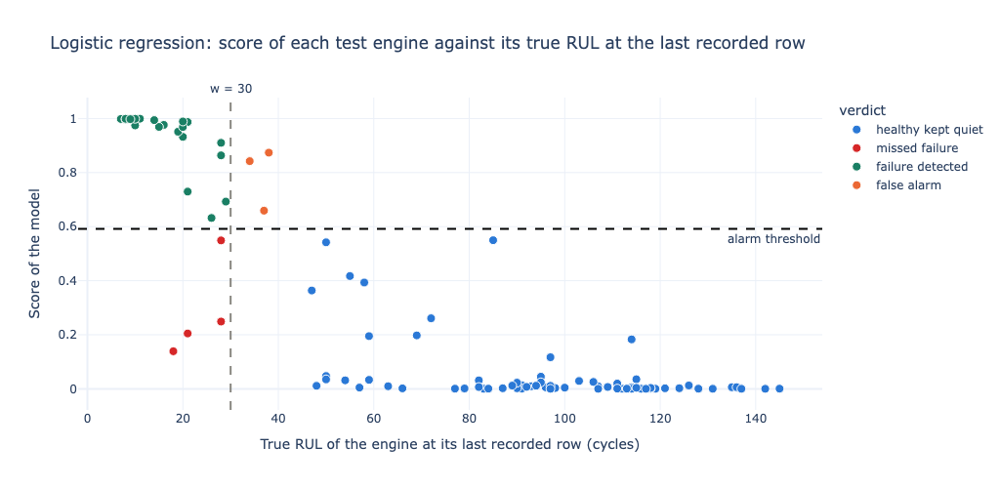

verdict
healthy kept quiet    72
failure detected      21
missed failure         4
false alarm            3


,unit,cycle,RUL,score,verdict,distance
0,18,133,28,0.249,missed failure,2
1,64,168,28,0.549,missed failure,2
2,77,162,34,0.842,false alarm,4
3,58,176,37,0.659,false alarm,7
4,91,234,38,0.874,false alarm,8
5,37,121,21,0.205,missed failure,9
6,41,123,18,0.139,missed failure,12


In [29]:
# One line per test engine: score, true RUL and verdict at the chosen threshold
errors = test_last[["unit", "cycle", "RUL", "y"]].copy()
errors["score"] = test_scores[CHOSEN]
errors["alarm"] = (errors["score"] >= THRESHOLD).astype(int)
errors["verdict"] = np.select([(errors["y"] == 1) & (errors["alarm"] == 1), (errors["y"] == 0) & (errors["alarm"] == 0),
                               (errors["y"] == 1) & (errors["alarm"] == 0)],
                              ["failure detected", "healthy kept quiet", "missed failure"], default="false alarm")

fig = px.scatter(errors, x="RUL", y="score", color="verdict", template=TEMPLATE, hover_data=["unit", "cycle"],
                 color_discrete_map={"failure detected": GREEN, "healthy kept quiet": BLUE, "missed failure": "#d62728", "false alarm": ORANGE},
                 title=f"{CHOSEN}: score of each test engine against its true RUL at the last recorded row")
fig.add_hline(y=THRESHOLD, line_dash="dash", line_color="black", annotation_text="alarm threshold", annotation_position="bottom right")
fig.add_vline(x=W, line_dash="dash", line_color=GREY, annotation_text=f"w = {W}", annotation_position="top")
fig.update_traces(marker=dict(size=9, line=dict(width=1, color="white")))
fig.update_layout(height=500, xaxis_title="True RUL of the engine at its last recorded row (cycles)", yaxis_title="Score of the model")
fig.show()

# The wrong engines, closest to the boundary first
wrong = errors[errors["verdict"].isin(["missed failure", "false alarm"])].assign(distance=lambda d: (d["RUL"] - W).abs())
print(errors["verdict"].value_counts().to_string())
wrong.sort_values("distance")[["unit", "cycle", "RUL", "score", "verdict", "distance"]].round(3).reset_index(drop=True)

<div style="background-color: rgba(210, 153, 34, 0.12); border-left: 4px solid #d29922; border-radius: 4px; padding: 4px 16px; margin-top: 8px;">

**Interpretation.**


**Reading the chart.** Each dot is a test engine at its last recorded row. The horizontal dashed line is the alarm threshold, the vertical one is the boundary $\text{RUL} = 30$. Green and blue dots are correct; red dots (below the threshold, left of the boundary) are missed failures; orange dots (above the threshold, right of the boundary) are false alarms.

**What it shows.**
- **All 7 errors are close to the boundary.** The 4 missed failures have a true RUL of 28, 28, 21 and 18 (2 to 12 cycles inside the boundary); the 3 false alarms have a RUL of 34, 37 and 38 (4 to 8 cycles outside it).
- **The errors are not random**: the model is wrong for engines that are, in truth, a few cycles from the line we drew ourselves. For a model that sees one row, an engine with 28 cycles left and one with 31 cycles left are nearly the same.
- **The false alarms are early warnings** rather than mistakes: an engine with 34 to 38 cycles left, flagged "failure imminent", is indeed close to its end.
- **The two misses at RUL 28** are the most costly in practice, yet the model could hardly be expected to separate them from RUL 31.

</div>

<a id="sub-9-2"></a>

---

### 9.2 The alarm along the life of the engines

<div style="background-color: rgba(31, 119, 180, 0.05); border-left: 4px solid rgba(31, 119, 180, 0.55); border-radius: 4px; padding: 4px 16px;">

On all the test rows, we compute the share of rows on which the model raises the alarm, for each number of cycles left. A good alarm is **off** far from the failure and **on** in the last 30 cycles.

</div>

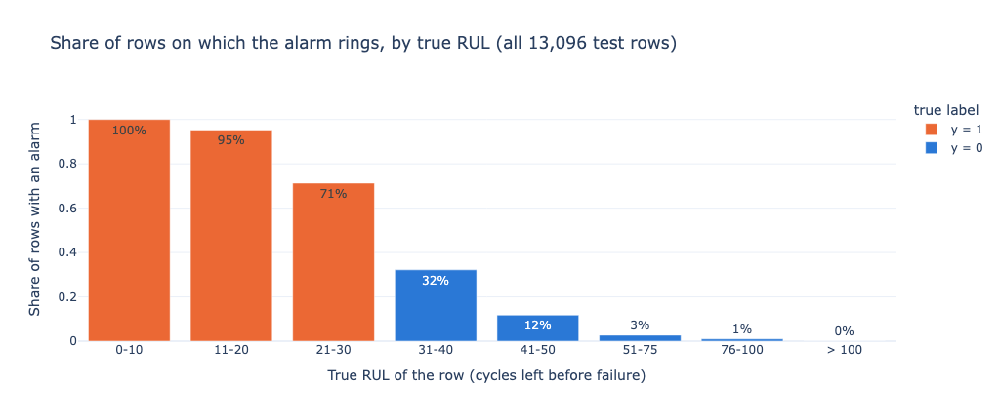

,share with an alarm,rows
band,,
0-10,100.0%,17
11-20,95.3%,106
21-30,71.3%,209
31-40,32.2%,264
41-50,11.7%,290
51-75,2.7%,973
76-100,1.0%,1335
> 100,0.0%,9902


In [30]:
# Share of alarms by band of true RUL, on all the test rows
bands = pd.cut(test["RUL"], bins=[-1, 10, 20, 30, 40, 50, 75, 100, 400],
               labels=["0-10", "11-20", "21-30", "31-40", "41-50", "51-75", "76-100", "> 100"])
profile = pd.DataFrame({"alarm": (all_scores >= THRESHOLD).astype(int), "band": bands}).groupby("band", observed=True)["alarm"].agg(["mean", "size"])
profile.columns = ["share with an alarm", "rows"]

fig = px.bar(profile.reset_index(), x="band", y="share with an alarm", text=profile["share with an alarm"].map("{:.0%}".format),
             template=TEMPLATE, color=["y = 1"] * 3 + ["y = 0"] * 5, color_discrete_map={"y = 1": ORANGE, "y = 0": BLUE},
             title="Share of rows on which the alarm rings, by true RUL (all 13,096 test rows)")
fig.update_layout(height=430, xaxis_title="True RUL of the row (cycles left before failure)", yaxis_title="Share of rows with an alarm",
                  yaxis_range=[0, 1.1], legend_title="true label")
fig.show()
profile.assign(**{"share with an alarm": profile["share with an alarm"].map("{:.1%}".format)})

<div style="background-color: rgba(210, 153, 34, 0.12); border-left: 4px solid #d29922; border-radius: 4px; padding: 4px 16px; margin-top: 8px;">

**Interpretation.**


**Reading the chart.** Each bar is the share of the test rows, in a band of true RUL, on which the model rings the alarm. Orange bars are the bands where an alarm is right ($y = 1$); blue bars the bands where it is wrong.

**What it shows.**
- **The alarm follows the life of the engines**: it rings on 100% of the rows in the last 10 cycles and 95% from 11 to 20 cycles; it is quiet on 99.9% of the rows with more than 75 cycles left (over 11,000 rows).
- **The transition is gradual, not abrupt**: 71% of the alarms in the band 21 to 30, then 32% in 31 to 40 and 12% in 41 to 50. The model does not see a wall at 30 cycles, because the degradation does not have one.
- **This explains the precision of the all-rows view.** The false alarms of [section 8.4](#sub-8-4) are overwhelmingly in the bands 31 to 50 cycles: about 85 + 34 = 119 of the roughly 160 false alarms. Those alarms come 1 to 20 cycles too early, not at random.
- **Practical reading**: an alarm with more than 50 cycles left is very rare (under 3%), so an alarm means "plan the maintenance soon".

</div>

---

<a id="conclusion-9"></a>

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px;">

### 9.3 Conclusion

**Goal of the section**: Find out whether the errors are random or follow a pattern.

**What we found.**

- **All 7 errors on the 100 test engines are within 12 cycles of the boundary** $\text{RUL} = 30$ (2 to 9 cycles for 6 of them).
- **The false alarms are early alarms**, 4 to 8 cycles before the window starts for the test engines, and mostly 1 to 20 cycles before the window starts over all the rows.
- **The alarm follows the degradation**: 95 to 100% in the last 20 cycles, under 3% beyond 50 cycles.


**Link with the other sections.** These patterns frame what the project can claim, in [section 10](#section-10).

<a href="#section-9">Back to the start of the section</a>

</div>

<a id="section-10"></a>

<div style="background-color: rgba(31, 119, 180, 0.14); border-left: 8px solid #1f77b4; border-radius: 6px; padding: 2px 16px; margin-top: 28px;">

## 10. What we learned

</div>

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px; margin-top: 14px;">

- **Why**: The decisions are spread over nine sections; this is the answer of the project and its limits, in one place.

</div>

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px; margin-top: 14px;">

**The answer to the project.** A logistic regression on the 14 standardised sensors, with an alarm threshold of 0.592, detects **21 of the 25 test engines whose failure is imminent** (RUL $\le$ 30), with **3 false alarms** on 75 healthy engines (recall 0.84, precision 0.875, F1 0.857, AUC 0.978).

| Finding | Evidence | Consequence |
|---|---|---|
| Accuracy is not informative here | the model that detects nothing has 85% | read recall, precision, F1, AUC and AP |
| Many models reach the same ranking quality | AUC 0.985 to 0.990 and AP 0.948 to 0.955 for six models, within a noise of 0.01 | take the simplest, logistic regression |
| A linear model is enough | logistic regression is among the leaders | no need for a complex model |
| `s9` and `s14` are useful in combination | AP drops by 0.018 to 0.030 without them, for five models out of five | the 14 sensors are kept |
| Class weights move the threshold, they do not improve the ranking | AUC and AP unchanged, recall +0.11 and precision -0.15 | the threshold is chosen explicitly |
| Tuning matters for a few models only | +0.094 for the SVM, 0.000 to 0.003 for most | do not compare untuned models |
| The cross-validation was a fair forecast | its scores are inside the 95% intervals of the test | the validation by engine was the right protocol |
| 100 test engines are few | recall between 0.67 and 0.96 | do not over-read a gap of a few points |
| The errors sit at the boundary | 7 of 7 within 12 cycles of $\text{RUL} = 30$ | they come from the boundary we drew, not from a blind spot |

**Limits.**
- 100 test engines, 25 at risk: the intervals are wide and the models cannot be ranked on the test.
- A prediction uses **one row**, without the history of the engine. The exploration had warned that a single row is an imprecise picture.
- The threshold maximises F2, which supposes that a missed failure costs about twice as much attention as a false alarm. A real cost would be needed to settle it.
- The window $w = 30$ is our choice. Another window gives another problem (section 5.7 of the exploration).
- FD001 has one flight condition and one fault mode: nothing is claimed for FD002 to FD004.

</div>

<a id="section-next"></a>

<div style="background-color: rgba(31, 119, 180, 0.14); border-left: 8px solid #1f77b4; border-radius: 6px; padding: 2px 16px; margin-top: 28px;">

## Going further

</div>

<div style="background-color: rgba(130, 80, 223, 0.08); border-left: 6px solid #8250df; border-radius: 6px; padding: 4px 16px; margin-top: 14px;">

This closes the second stage of the project (*Modélisation et évaluation*).

**Ideas to go further**, ordered by expected gain:
1. **Give the model the history of each engine**: moving averages and slopes of the sensors over the last 5 to 30 cycles, computed engine by engine. This addresses the main limit above, and the errors at the boundary are the ones it should reduce.
2. **Use a cost for the threshold** instead of F2, if the cost of a missed failure and of a false alarm are known.
3. **Try other windows** ($w = 20$ or $50$) and check how recall, precision and the lead time of the alarm change.
4. **Predict the RUL itself** with a regression model, then apply the threshold to its output.
5. **Move to FD002 to FD004**, with several flight conditions, where the sensors would have to be normalised by condition.

</div>